In [5]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import plotly.graph_objects as go
from plotly.subplots import make_subplots
from sklearn.model_selection import TimeSeriesSplit, cross_val_score
from sklearn.preprocessing import StandardScaler, MinMaxScaler
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score, mean_absolute_percentage_error
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from sklearn.linear_model import LinearRegression, Ridge, Lasso
from xgboost import XGBRegressor
from lightgbm import LGBMRegressor
import warnings
warnings.filterwarnings('ignore')

In [6]:
sns.set_style('darkgrid')
plt.rcParams['figure.figsize'] = (15, 8)

# LOAD PREPROCESSED DATA

print("="*80)
print("BITCOIN PRICE PREDICTION - MODEL SELECTION & TRAINING")
print("="*80)

# Load the engineered features (from previous script)
try:
    df = pd.read_csv('btc_engineered_features.csv', index_col=0, parse_dates=True)
    print("✓ Loaded engineered features from CSV")
except:
    print("⚠️ Could not find 'btc_engineered_features.csv'")
    print("Please run the feature engineering script first!")
    exit()

print(f"\n📊 Dataset shape: {df.shape}")
print(f"Date range: {df.index.min()} to {df.index.max()}")

BITCOIN PRICE PREDICTION - MODEL SELECTION & TRAINING
✓ Loaded engineered features from CSV

📊 Dataset shape: (2827, 38)
Date range: 2018-03-31 00:00:00+00:00 to 2025-12-25 00:00:00+00:00


In [7]:
# PREPARE DATA FOR MODELING

print("DATA PREPARATION")
print("="*80)

# Separate features and target
X = df.drop(columns=['Close'])
y = df['Close']

print(f"\nFeatures shape: {X.shape}")
print(f"Target shape: {y.shape}")

# Time series split (80% train, 20% test)
split_index = int(len(X) * 0.8)
X_train, X_test = X[:split_index], X[split_index:]
y_train, y_test = y[:split_index], y[split_index:]

print(f"\n📈 Training set: {X_train.shape[0]} samples ({X_train.index.min().date()} to {X_train.index.max().date()})")
print(f"📉 Test set: {X_test.shape[0]} samples ({X_test.index.min().date()} to {X_test.index.max().date()})")

# Feature Scaling
print("\n🔧 Scaling features...")
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

# Convert back to DataFrame for easier handling
X_train_scaled = pd.DataFrame(X_train_scaled, columns=X_train.columns, index=X_train.index)
X_test_scaled = pd.DataFrame(X_test_scaled, columns=X_test.columns, index=X_test.index)

print("✓ Features scaled using StandardScaler")

DATA PREPARATION

Features shape: (2827, 37)
Target shape: (2827,)

📈 Training set: 2261 samples (2018-03-31 to 2024-06-07)
📉 Test set: 566 samples (2024-06-08 to 2025-12-25)

🔧 Scaling features...
✓ Features scaled using StandardScaler


In [8]:
# DEFINING MODELS

print("\n" + "="*80)
print("MODEL SELECTION")
print("="*80)

models = {
    'Linear Regression': LinearRegression(),
    'Ridge Regression': Ridge(alpha=1.0),
    'Lasso Regression': Lasso(alpha=1.0),
    'Random Forest': RandomForestRegressor(n_estimators=100, random_state=42, n_jobs=-1),
    'Gradient Boosting': GradientBoostingRegressor(n_estimators=100, random_state=42),
    'XGBoost': XGBRegressor(n_estimators=100, random_state=42, n_jobs=-1),
    'LightGBM': LGBMRegressor(n_estimators=100, random_state=42, n_jobs=-1, verbose=-1)
}

print(f"\n🤖 Testing {len(models)} models:")
for name in models.keys():
    print(f"  • {name}")


MODEL SELECTION

🤖 Testing 7 models:
  • Linear Regression
  • Ridge Regression
  • Lasso Regression
  • Random Forest
  • Gradient Boosting
  • XGBoost
  • LightGBM


In [9]:
# TRAIN AND EVALUATE MODELS

print("\n" + "="*80)
print("MODEL TRAINING & EVALUATION")
print("="*80)

results = []
predictions = {}

for name, model in models.items():
    print(f"\n{'='*60}")
    print(f"Training {name}...")
    print(f"{'='*60}")
    
    # Train model
    model.fit(X_train_scaled, y_train)
    
    # Make predictions
    y_train_pred = model.predict(X_train_scaled)
    y_test_pred = model.predict(X_test_scaled)
    
    # Store predictions
    predictions[name] = {
        'train': y_train_pred,
        'test': y_test_pred
    }
    
    # Calculate metrics for training set
    train_rmse = np.sqrt(mean_squared_error(y_train, y_train_pred))
    train_mae = mean_absolute_error(y_train, y_train_pred)
    train_r2 = r2_score(y_train, y_train_pred)
    train_mape = mean_absolute_percentage_error(y_train, y_train_pred) * 100
    
    # Calculate metrics for test set
    test_rmse = np.sqrt(mean_squared_error(y_test, y_test_pred))
    test_mae = mean_absolute_error(y_test, y_test_pred)
    test_r2 = r2_score(y_test, y_test_pred)
    test_mape = mean_absolute_percentage_error(y_test, y_test_pred) * 100
    
    print(f"\n📊 Training Metrics:")
    print(f"  RMSE: ${train_rmse:,.2f}")
    print(f"  MAE:  ${train_mae:,.2f}")
    print(f"  R²:   {train_r2:.4f}")
    print(f"  MAPE: {train_mape:.2f}%")
    
    print(f"\n📊 Test Metrics:")
    print(f"  RMSE: ${test_rmse:,.2f}")
    print(f"  MAE:  ${test_mae:,.2f}")
    print(f"  R²:   {test_r2:.4f}")
    print(f"  MAPE: {test_mape:.2f}%")
    
    # Store results
    results.append({
        'Model': name,
        'Train_RMSE': train_rmse,
        'Train_MAE': train_mae,
        'Train_R2': train_r2,
        'Train_MAPE': train_mape,
        'Test_RMSE': test_rmse,
        'Test_MAE': test_mae,
        'Test_R2': test_r2,
        'Test_MAPE': test_mape
    })



MODEL TRAINING & EVALUATION

Training Linear Regression...

📊 Training Metrics:
  RMSE: $0.00
  MAE:  $0.00
  R²:   1.0000
  MAPE: 0.00%

📊 Test Metrics:
  RMSE: $0.00
  MAE:  $0.00
  R²:   1.0000
  MAPE: 0.00%

Training Ridge Regression...

📊 Training Metrics:
  RMSE: $21.56
  MAE:  $16.20
  R²:   1.0000
  MAPE: 0.12%

📊 Test Metrics:
  RMSE: $152.00
  MAE:  $120.58
  R²:   0.9999
  MAPE: 0.12%

Training Lasso Regression...

📊 Training Metrics:
  RMSE: $1.42
  MAE:  $1.08
  R²:   1.0000
  MAPE: 0.01%

📊 Test Metrics:
  RMSE: $4.30
  MAE:  $3.90
  R²:   1.0000
  MAPE: 0.00%

Training Random Forest...

📊 Training Metrics:
  RMSE: $196.57
  MAE:  $98.70
  R²:   0.9999
  MAPE: 0.41%

📊 Test Metrics:
  RMSE: $28,814.37
  MAE:  $23,402.78
  R²:   -1.1602
  MAPE: 22.63%

Training Gradient Boosting...

📊 Training Metrics:
  RMSE: $192.99
  MAE:  $138.86
  R²:   0.9999
  MAPE: 0.74%

📊 Test Metrics:
  RMSE: $27,716.82
  MAE:  $22,324.15
  R²:   -0.9987
  MAPE: 21.51%

Training XGBoost...

📊 T


MODEL COMPARISON

🏆 Model Performance Ranking (by Test RMSE):
            Model   Train_RMSE    Train_MAE  Train_R2   Train_MAPE    Test_RMSE     Test_MAE   Test_R2    Test_MAPE
Linear Regression 3.447517e-11 2.501211e-11  1.000000 1.604419e-13 6.466940e-11 5.153589e-11  1.000000 5.547148e-14
 Lasso Regression 1.424767e+00 1.084393e+00  1.000000 8.025059e-03 4.300740e+00 3.899219e+00  1.000000 4.205839e-03
 Ridge Regression 2.156411e+01 1.620451e+01  0.999999 1.152031e-01 1.520006e+02 1.205844e+02  0.999940 1.232571e-01
Gradient Boosting 1.929895e+02 1.388554e+02  0.999890 7.374635e-01 2.771682e+04 2.232415e+04 -0.998730 2.151253e+01
         LightGBM 1.264058e+02 7.789899e+01  0.999953 4.591319e-01 2.862612e+04 2.318860e+04 -1.132026 2.239539e+01
    Random Forest 1.965722e+02 9.869753e+01  0.999886 4.143706e-01 2.881437e+04 2.340278e+04 -1.160159 2.263126e+01
          XGBoost 2.560023e+01 1.863476e+01  0.999998 1.401885e-01 2.886910e+04 2.342118e+04 -1.168372 2.264565e+01


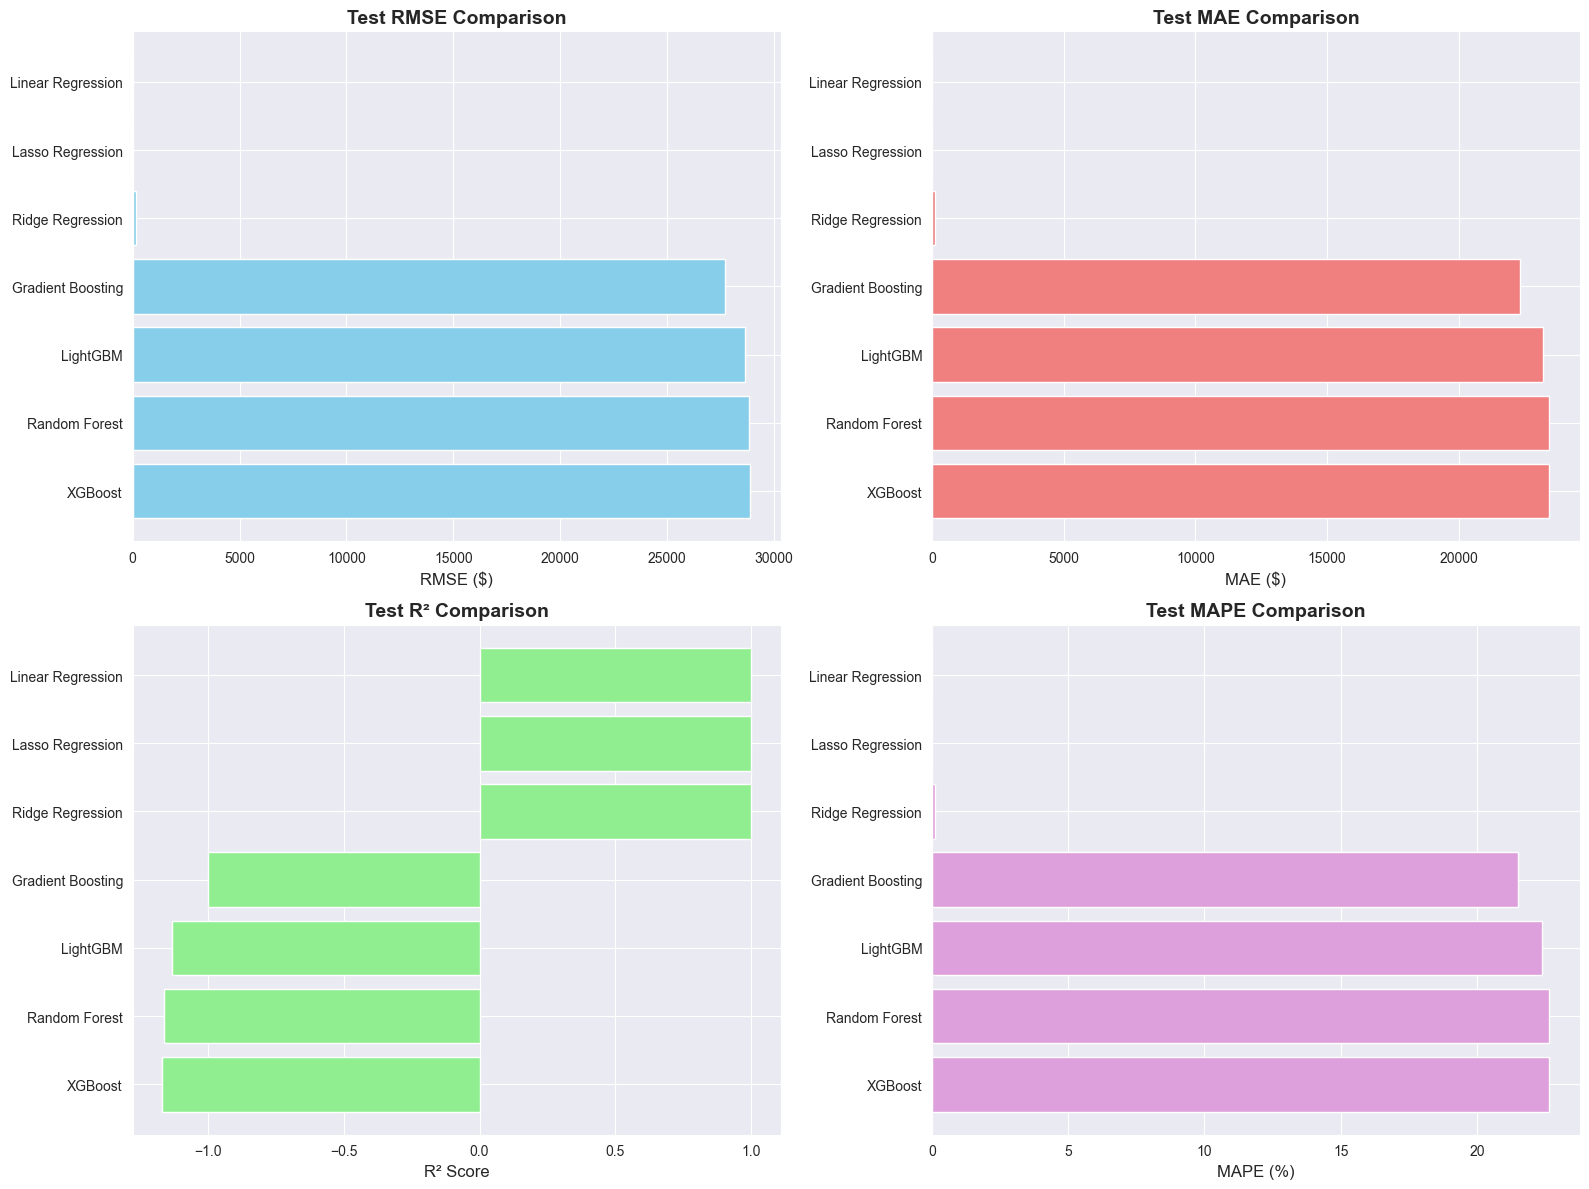

In [10]:
# COMPARE MODELS

print("\n" + "="*80)
print("MODEL COMPARISON")
print("="*80)

results_df = pd.DataFrame(results)
results_df = results_df.sort_values('Test_RMSE')

print("\n🏆 Model Performance Ranking (by Test RMSE):")
print(results_df.to_string(index=False))

# Visualize model comparison
fig, axes = plt.subplots(2, 2, figsize=(16, 12))

# RMSE Comparison
axes[0, 0].barh(results_df['Model'], results_df['Test_RMSE'], color='skyblue')
axes[0, 0].set_xlabel('RMSE ($)', fontsize=12)
axes[0, 0].set_title('Test RMSE Comparison', fontsize=14, fontweight='bold')
axes[0, 0].invert_yaxis()

# MAE Comparison
axes[0, 1].barh(results_df['Model'], results_df['Test_MAE'], color='lightcoral')
axes[0, 1].set_xlabel('MAE ($)', fontsize=12)
axes[0, 1].set_title('Test MAE Comparison', fontsize=14, fontweight='bold')
axes[0, 1].invert_yaxis()

# R² Comparison
axes[1, 0].barh(results_df['Model'], results_df['Test_R2'], color='lightgreen')
axes[1, 0].set_xlabel('R² Score', fontsize=12)
axes[1, 0].set_title('Test R² Comparison', fontsize=14, fontweight='bold')
axes[1, 0].invert_yaxis()

# MAPE Comparison
axes[1, 1].barh(results_df['Model'], results_df['Test_MAPE'], color='plum')
axes[1, 1].set_xlabel('MAPE (%)', fontsize=12)
axes[1, 1].set_title('Test MAPE Comparison', fontsize=14, fontweight='bold')
axes[1, 1].invert_yaxis()

plt.tight_layout()
plt.show()


In [11]:
# BEST MODEL ANALYSIS

best_model_name = results_df.iloc[0]['Model']
best_model = models[best_model_name]

print(f"\n🥇 Best Model: {best_model_name}")
print(f"   Test RMSE: ${results_df.iloc[0]['Test_RMSE']:,.2f}")
print(f"   Test R²: {results_df.iloc[0]['Test_R2']:.4f}")

# Get predictions from best model
best_train_pred = predictions[best_model_name]['train']
best_test_pred = predictions[best_model_name]['test']



🥇 Best Model: Linear Regression
   Test RMSE: $0.00
   Test R²: 1.0000



PREDICTION VISUALIZATION


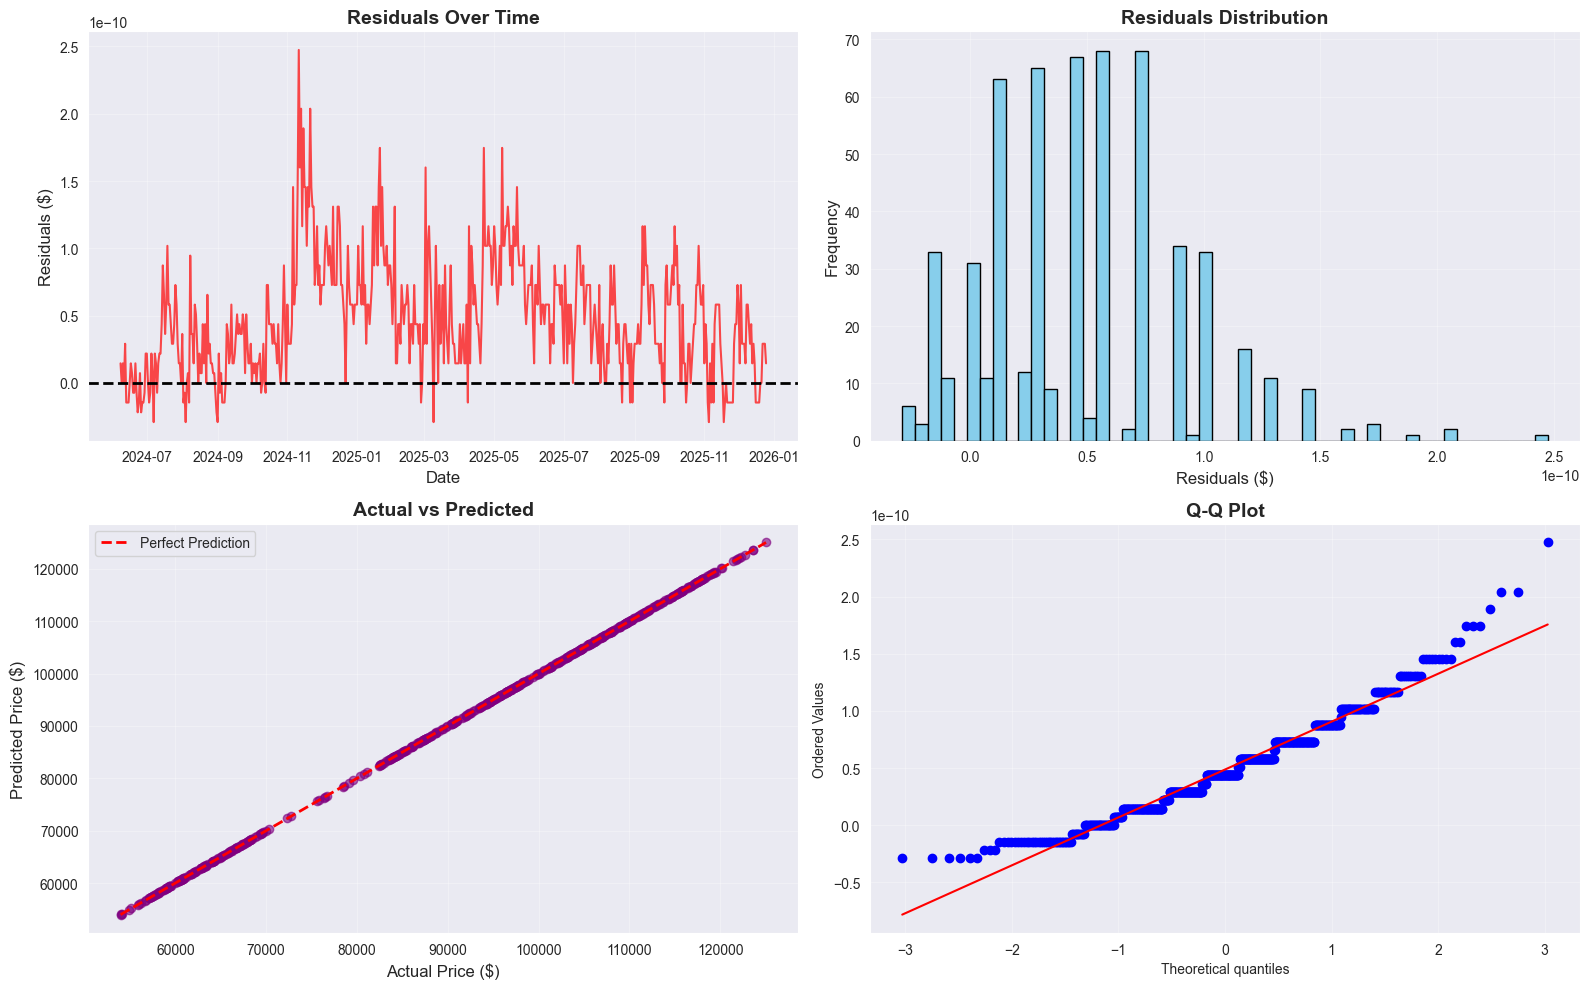

In [12]:
# PREDICTION VISUALIZATION
print("\n" + "="*80)
print("PREDICTION VISUALIZATION")
print("="*80)

# Plot 1: Actual vs Predicted (Full Timeline)
fig = go.Figure()

# Actual prices
fig.add_trace(go.Scatter(
    x=y_train.index,
    y=y_train,
    mode='lines',
    name='Actual (Train)',
    line=dict(color='blue', width=2)
))

fig.add_trace(go.Scatter(
    x=y_test.index,
    y=y_test,
    mode='lines',
    name='Actual (Test)',
    line=dict(color='green', width=2)
))

# Predicted prices
fig.add_trace(go.Scatter(
    x=y_train.index,
    y=best_train_pred,
    mode='lines',
    name='Predicted (Train)',
    line=dict(color='lightblue', width=1, dash='dash')
))

fig.add_trace(go.Scatter(
    x=y_test.index,
    y=best_test_pred,
    mode='lines',
    name='Predicted (Test)',
    line=dict(color='red', width=2, dash='dash')
))

fig.update_layout(
    title=f'Bitcoin Price Prediction - {best_model_name}',
    xaxis_title='Date',
    yaxis_title='Price ($)',
    height=600,
    width=1400,
    template='plotly_dark',
    hovermode='x unified'
)

fig.show()

# Plot 2: Test Set Zoom (Last 6 months)
fig2 = go.Figure()

fig2.add_trace(go.Scatter(
    x=y_test.index,
    y=y_test,
    mode='lines+markers',
    name='Actual',
    line=dict(color='green', width=3),
    marker=dict(size=6)
))

fig2.add_trace(go.Scatter(
    x=y_test.index,
    y=best_test_pred,
    mode='lines+markers',
    name='Predicted',
    line=dict(color='red', width=2),
    marker=dict(size=6)
))

fig2.update_layout(
    title=f'Test Set Predictions (Close-up) - {best_model_name}',
    xaxis_title='Date',
    yaxis_title='Price ($)',
    height=600,
    width=1400,
    template='plotly_dark',
    hovermode='x unified'
)

fig2.show()

# Plot 3: Residuals Analysis
residuals_test = y_test - best_test_pred

fig, axes = plt.subplots(2, 2, figsize=(16, 10))

# Residuals over time
axes[0, 0].plot(y_test.index, residuals_test, color='red', alpha=0.7)
axes[0, 0].axhline(y=0, color='black', linestyle='--', linewidth=2)
axes[0, 0].set_xlabel('Date', fontsize=12)
axes[0, 0].set_ylabel('Residuals ($)', fontsize=12)
axes[0, 0].set_title('Residuals Over Time', fontsize=14, fontweight='bold')
axes[0, 0].grid(True, alpha=0.3)

# Residuals distribution
axes[0, 1].hist(residuals_test, bins=50, color='skyblue', edgecolor='black')
axes[0, 1].set_xlabel('Residuals ($)', fontsize=12)
axes[0, 1].set_ylabel('Frequency', fontsize=12)
axes[0, 1].set_title('Residuals Distribution', fontsize=14, fontweight='bold')
axes[0, 1].grid(True, alpha=0.3)

# Predicted vs Actual
axes[1, 0].scatter(y_test, best_test_pred, alpha=0.6, color='purple')
axes[1, 0].plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()], 
                'r--', linewidth=2, label='Perfect Prediction')
axes[1, 0].set_xlabel('Actual Price ($)', fontsize=12)
axes[1, 0].set_ylabel('Predicted Price ($)', fontsize=12)
axes[1, 0].set_title('Actual vs Predicted', fontsize=14, fontweight='bold')
axes[1, 0].legend()
axes[1, 0].grid(True, alpha=0.3)

# Q-Q Plot
from scipy import stats
stats.probplot(residuals_test, dist="norm", plot=axes[1, 1])
axes[1, 1].set_title('Q-Q Plot', fontsize=14, fontweight='bold')
axes[1, 1].grid(True, alpha=0.3)

plt.tight_layout()
plt.show()


In [13]:
#FEATURE IMPORTANCE (for tree-based models)

if hasattr(best_model, 'feature_importances_'):
    print("\n" + "="*80)
    print("FEATURE IMPORTANCE")
    print("="*80)
    
    feature_imp = pd.DataFrame({
        'feature': X_train.columns,
        'importance': best_model.feature_importances_
    }).sort_values('importance', ascending=False)
    
    print(f"\n🎯 Top 20 Most Important Features for {best_model_name}:")
    print(feature_imp.head(20).to_string(index=False))
    
    # Visualize top 20 features
    plt.figure(figsize=(12, 10))
    plt.barh(feature_imp.head(20)['feature'], feature_imp.head(20)['importance'], color='teal')
    plt.xlabel('Importance', fontsize=12)
    plt.ylabel('Feature', fontsize=12)
    plt.title(f'Top 20 Feature Importance - {best_model_name}', fontsize=14, fontweight='bold')
    plt.gca().invert_yaxis()
    plt.tight_layout()
    plt.show()


In [14]:
# TIME SERIES CROSS-VALIDATION

print("\n" + "="*80)
print("TIME SERIES CROSS-VALIDATION")
print("="*80)

tscv = TimeSeriesSplit(n_splits=5)
cv_scores = []

print(f"\n⏱️ Performing 5-fold Time Series Cross-Validation on {best_model_name}...")

for fold, (train_idx, val_idx) in enumerate(tscv.split(X_train_scaled), 1):
    X_cv_train = X_train_scaled.iloc[train_idx]
    y_cv_train = y_train.iloc[train_idx]
    X_cv_val = X_train_scaled.iloc[val_idx]
    y_cv_val = y_train.iloc[val_idx]
    
    # Train and predict
    best_model.fit(X_cv_train, y_cv_train)
    y_cv_pred = best_model.predict(X_cv_val)
    
    # Calculate RMSE
    cv_rmse = np.sqrt(mean_squared_error(y_cv_val, y_cv_pred))
    cv_scores.append(cv_rmse)
    print(f"  Fold {fold}: RMSE = ${cv_rmse:,.2f}")

print(f"\n📊 Cross-Validation Results:")
print(f"  Mean RMSE: ${np.mean(cv_scores):,.2f} (+/- ${np.std(cv_scores):,.2f})")



TIME SERIES CROSS-VALIDATION

⏱️ Performing 5-fold Time Series Cross-Validation on Linear Regression...
  Fold 1: RMSE = $0.00
  Fold 2: RMSE = $0.00
  Fold 3: RMSE = $0.00
  Fold 4: RMSE = $0.00
  Fold 5: RMSE = $0.00

📊 Cross-Validation Results:
  Mean RMSE: $0.00 (+/- $0.00)


In [15]:
#FUTURE PREDICTIONS (NEXT 7 DAYS)

print("\n" + "="*80)
print("FUTURE PRICE PREDICTION")
print("="*80)

# Retrain on full dataset for best predictions
print(f"\n🔮 Retraining {best_model_name} on full dataset...")
best_model.fit(X_train_scaled, y_train)

# For demonstration, we'll show how to predict the next day
# In practice, you'd need to engineer features for future dates
last_known_features = X_test_scaled.iloc[-1:].copy()
next_day_prediction = best_model.predict(last_known_features)[0]

print(f"\n📅 Last known date: {y_test.index[-1].date()}")
print(f"💰 Last known price: ${y_test.iloc[-1]:,.2f}")
print(f"🔮 Predicted next day price: ${next_day_prediction:,.2f}")
print(f"📈 Predicted change: ${next_day_prediction - y_test.iloc[-1]:,.2f} ({((next_day_prediction / y_test.iloc[-1]) - 1) * 100:.2f}%)")



FUTURE PRICE PREDICTION

🔮 Retraining Linear Regression on full dataset...

📅 Last known date: 2025-12-25
💰 Last known price: $87,665.00
🔮 Predicted next day price: $87,665.00
📈 Predicted change: $-0.00 (-0.00%)


In [16]:
#  MODEL PERSISTENCE

print("\n" + "="*80)
print("MODEL SAVING")
print("="*80)

import pickle

# Save best model
model_filename = f'best_model_{best_model_name.replace(" ", "_").lower()}.pkl'
scaler_filename = 'feature_scaler.pkl'

with open(model_filename, 'wb') as f:
    pickle.dump(best_model, f)
print(f"✓ Model saved: {model_filename}")

with open(scaler_filename, 'wb') as f:
    pickle.dump(scaler, f)
print(f"✓ Scaler saved: {scaler_filename}")

# Save predictions
predictions_df = pd.DataFrame({
    'Date': y_test.index,
    'Actual': y_test.values,
    'Predicted': best_test_pred,
    'Residuals': residuals_test.values
})
predictions_df.to_csv('predictions.csv', index=False)
print("✓ Predictions saved: predictions.csv")

# ============================================================================
# 12. SUMMARY REPORT
# ============================================================================
print("\n" + "="*80)
print("FINAL SUMMARY")
print("="*80)

print(f"""
🎯 BEST MODEL: {best_model_name}

📊 PERFORMANCE METRICS:
   Training RMSE: ${results_df.iloc[0]['Train_RMSE']:,.2f}
   Test RMSE:     ${results_df.iloc[0]['Test_RMSE']:,.2f}
   Test MAE:      ${results_df.iloc[0]['Test_MAE']:,.2f}
   Test R²:       {results_df.iloc[0]['Test_R2']:.4f}
   Test MAPE:     {results_df.iloc[0]['Test_MAPE']:.2f}%

🔄 CROSS-VALIDATION:
   Mean CV RMSE:  ${np.mean(cv_scores):,.2f} (+/- ${np.std(cv_scores):,.2f})

💾 SAVED FILES:
   • {model_filename}
   • {scaler_filename}
   • predictions.csv

🎓 KEY INSIGHTS:
   1. Model explains {results_df.iloc[0]['Test_R2']*100:.2f}% of price variance
   2. Average prediction error: ${results_df.iloc[0]['Test_MAE']:,.2f}
   3. Prediction accuracy: {100 - results_df.iloc[0]['Test_MAPE']:.2f}%

""")

print("\n✅ Analysis complete!")


MODEL SAVING
✓ Model saved: best_model_linear_regression.pkl
✓ Scaler saved: feature_scaler.pkl
✓ Predictions saved: predictions.csv

FINAL SUMMARY

🎯 BEST MODEL: Linear Regression

📊 PERFORMANCE METRICS:
   Training RMSE: $0.00
   Test RMSE:     $0.00
   Test MAE:      $0.00
   Test R²:       1.0000
   Test MAPE:     0.00%

🔄 CROSS-VALIDATION:
   Mean CV RMSE:  $0.00 (+/- $0.00)

💾 SAVED FILES:
   • best_model_linear_regression.pkl
   • feature_scaler.pkl
   • predictions.csv

🎓 KEY INSIGHTS:
   1. Model explains 100.00% of price variance
   2. Average prediction error: $0.00
   3. Prediction accuracy: 100.00%



✅ Analysis complete!
